In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from skimage.io import imread
PHENOTYPE_NAMES = {
    1: "Vegetative",
    2: "Shmoo",
    3: "Fusion",
    4: "Ascus",
    5: "Lysis",
    6: "Spores",
}

PHENOTYPE_COLORS = {
    1: "#E45756",
    2: "#54A24B",
    3: "#4C78A8",
    4: "#F58518",
    5: "#B279A2",
    6: "#72B7B2",
}


def plot_tsne(
    coordinates,
    labels,
    output_path=None,
    cutoff_number=500,
    random_state=42,
    class_ids=range(1, 7),
):
    """
    Plot a publication-style t-SNE figure.

    Parameters
    ----------
    coordinates : array-like, shape (n_samples, 2)
        Calculated t-SNE coordinates.

    labels : array-like, shape (n_samples,)
        Class labels.

    output_path : str or Path, optional
        Save as PDF/SVG for vector output or PNG/TIFF at 600 dpi.

    cutoff_number : int or None
        Maximum number of displayed samples per class.
        Use None to display all samples.

    random_state : int
        Seed used for reproducible random subsampling.

    class_ids : iterable
        Classes to display.
    """
    coordinates = np.asarray(coordinates)
    labels = np.asarray(labels)

    if coordinates.shape[0] != labels.shape[0]:
        raise ValueError(
            "coordinates and labels must contain the same "
            "number of samples."
        )

    rng = np.random.default_rng(random_state)

    fig, ax = plt.subplots(
        figsize=(3.5, 3.2),
        dpi=300,
    )

    for class_id in class_ids:
        all_indices = np.flatnonzero(labels == class_id)
        total_number = len(all_indices)

        if total_number == 0:
            continue

        if (
            cutoff_number is not None
            and total_number > cutoff_number
        ):
            plot_indices = rng.choice(
                all_indices,
                size=cutoff_number,
                replace=False,
            )
        else:
            plot_indices = all_indices

        phenotype_name = PHENOTYPE_NAMES.get(
            int(class_id),
            f"Class {class_id}",
        )
        color = PHENOTYPE_COLORS.get(
            int(class_id),
            "#808080",
        )

        ax.scatter(
            coordinates[plot_indices, 0],
            coordinates[plot_indices, 1],
            s=8,
            color=color,
            alpha=0.7,
            edgecolors="none",
            rasterized=True,
            label=(
                f"{phenotype_name} "
                f"(shown {len(plot_indices):,}/{total_number:,})"
            ),
        )

    ax.set_xlabel("t-SNE 1", fontsize=8)
    ax.set_ylabel("t-SNE 2", fontsize=8)

    # Absolute t-SNE coordinate values are not interpretable
    ax.set_xticks([])
    ax.set_yticks([])

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(0.8)
    ax.spines["bottom"].set_linewidth(0.8)

    ax.legend(
        frameon=False,
        fontsize=7,
        markerscale=1.5,
        handletextpad=0.4,
        labelspacing=0.35,
        borderaxespad=0,
        loc="upper left",
        # bbox_to_anchor=(1.02, 1),
    )

    fig.tight_layout()

    if output_path is not None:
        output_path = Path(output_path)
        output_path.parent.mkdir(
            parents=True,
            exist_ok=True,
        )

        save_kwargs = {
            "bbox_inches": "tight",
            "pad_inches": 0.03,
            "transparent": True,
        }

        if output_path.suffix.lower() in {
            ".png",
            ".tif",
            ".tiff",
        }:
            save_kwargs["dpi"] = 600

        fig.savefig(
            output_path,
            **save_kwargs,
        )

    # plt.show()

    return fig, ax

def get_original_name(image_name):
    """Remove crop-position suffix from a filename."""
    for suffix in (
        "_top_left",
        "_top_right",
        "_bottom_left",
        "_bottom_right",
    ):
        image_name = image_name.replace(suffix, "")
    return image_name


import numpy as np


def merge_embedding_results(*result_dicts):
    """
    Merge embedding-result dictionaries and remove repeated instances.

    Duplicate identity:
        (image_names, panoptic_ids)

    If duplicates exist, retain the row with the largest pixel_counts.
    """
    if len(result_dicts) == 0:
        raise ValueError("Provide at least one result dictionary.")

    required_keys = {
        "embeddings",
        "labels",
        "panoptic_ids",
        "instance_ids",
        "image_names",
        "image_positions",
        "pixel_counts",
    }

    for i, result in enumerate(result_dicts):
        missing = required_keys - result.keys()
        if missing:
            raise KeyError(
                f"Dictionary {i} is missing keys: {sorted(missing)}"
            )

        n = len(result["labels"])

        for key in required_keys:
            if len(result[key]) != n:
                raise ValueError(
                    f"Dictionary {i}: {key!r} has "
                    f"{len(result[key])} rows, expected {n}."
                )

    # Merge every field
    merged = {
        key: np.concatenate(
            [np.asarray(result[key]) for result in result_dicts],
            axis=0,
        )
        for key in required_keys
    }

    # Sort so that the largest occurrence of each instance comes first.
    order = np.argsort(-merged["pixel_counts"], kind="stable")

    # np.unique sorts keys, so return_index identifies the first occurrence
    # after sorting, which is the largest occurrence.
    duplicate_keys = np.rec.fromarrays(
        [
            merged["image_names"][order].astype(str),
            merged["panoptic_ids"][order],
        ],
        names=("image_name", "panoptic_id"),
    )

    _, first_indices = np.unique(
        duplicate_keys,
        return_index=True,
    )

    keep_indices = order[first_indices]

    # Restore the original combined ordering
    keep_indices.sort()

    deduplicated = {
        key: values[keep_indices]
        for key, values in merged.items()
    }

    print(f"Rows before removing duplicates: {len(merged['labels'])}")
    print(f"Rows after removing duplicates:  {len(deduplicated['labels'])}")
    print(
        "Duplicates removed:              "
        f"{len(merged['labels']) - len(deduplicated['labels'])}"
    )

    return deduplicated

from contrast_learning import calculate_tsne

/home/liwa/miniconda3/envs/oneformer/lib/python3.8/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import pickle
with open("contrast_embedding_selected_3ch_crop512.pkl", "rb") as f:
    results_1 = pickle.load(f)
with open("contrast_embedding_selected_3ch_crop512_test_10001_10130.pkl", "rb") as f:
    results_2 = pickle.load(f)


results = merge_embedding_results(results_1,results_2,)

Rows before removing duplicates: 14178
Rows after removing duplicates:  13751
Duplicates removed:              427


In [3]:
from tqdm import trange

  0%|                                                                                                                                                                                | 0/10 [00:00<?, ?it/s]

Running t-SNE: samples=13751, dimensions=32, perplexity=50


 10%|████████████████▊                                                                                                                                                       | 1/10 [01:01<09:11, 61.31s/it]

Running t-SNE: samples=13751, dimensions=32, perplexity=100


 20%|█████████████████████████████████▌                                                                                                                                      | 2/10 [02:21<09:40, 72.53s/it]

...

 80%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▌                                 | 8/10 [20:33<06:30, 195.29s/it]

Running t-SNE: samples=13751, dimensions=32, perplexity=450


 90%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▎                | 9/10 [25:00<03:37, 217.71s/it]

Running t-SNE: samples=13751, dimensions=32, perplexity=500


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 10/10 [29:52<00:00, 179.23s/it]


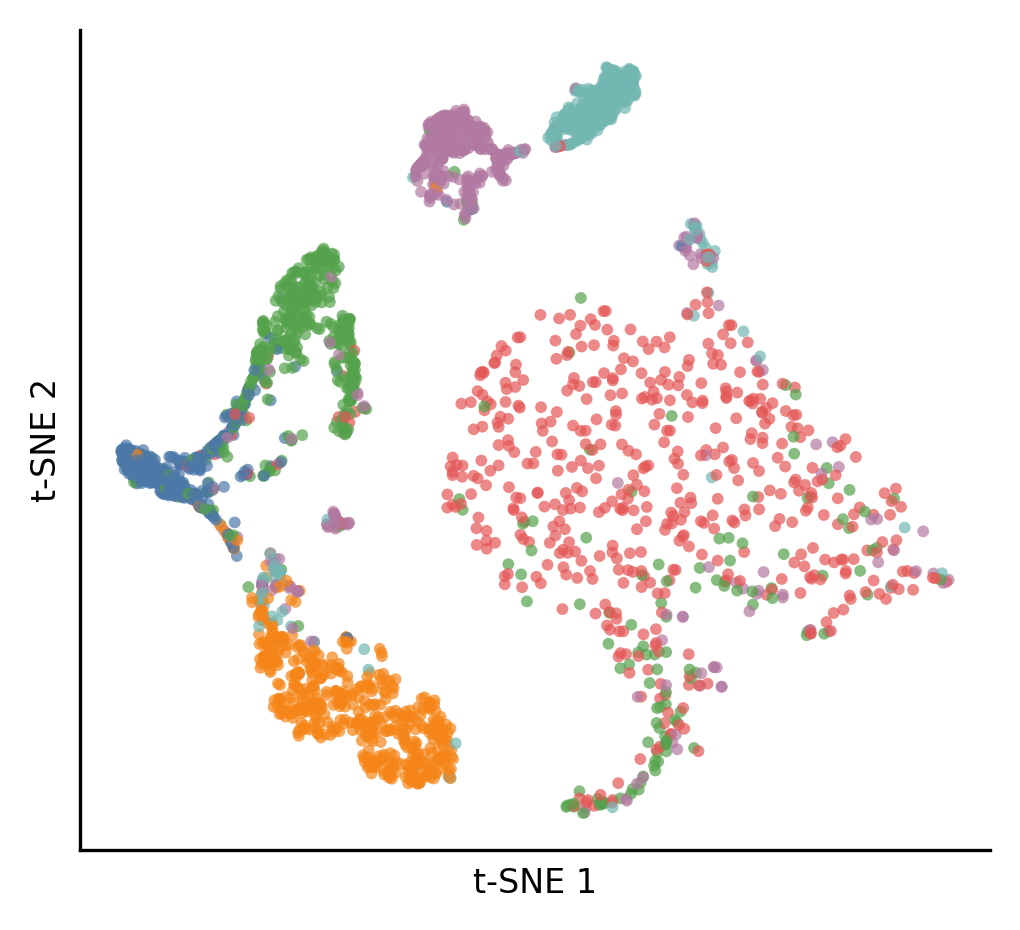

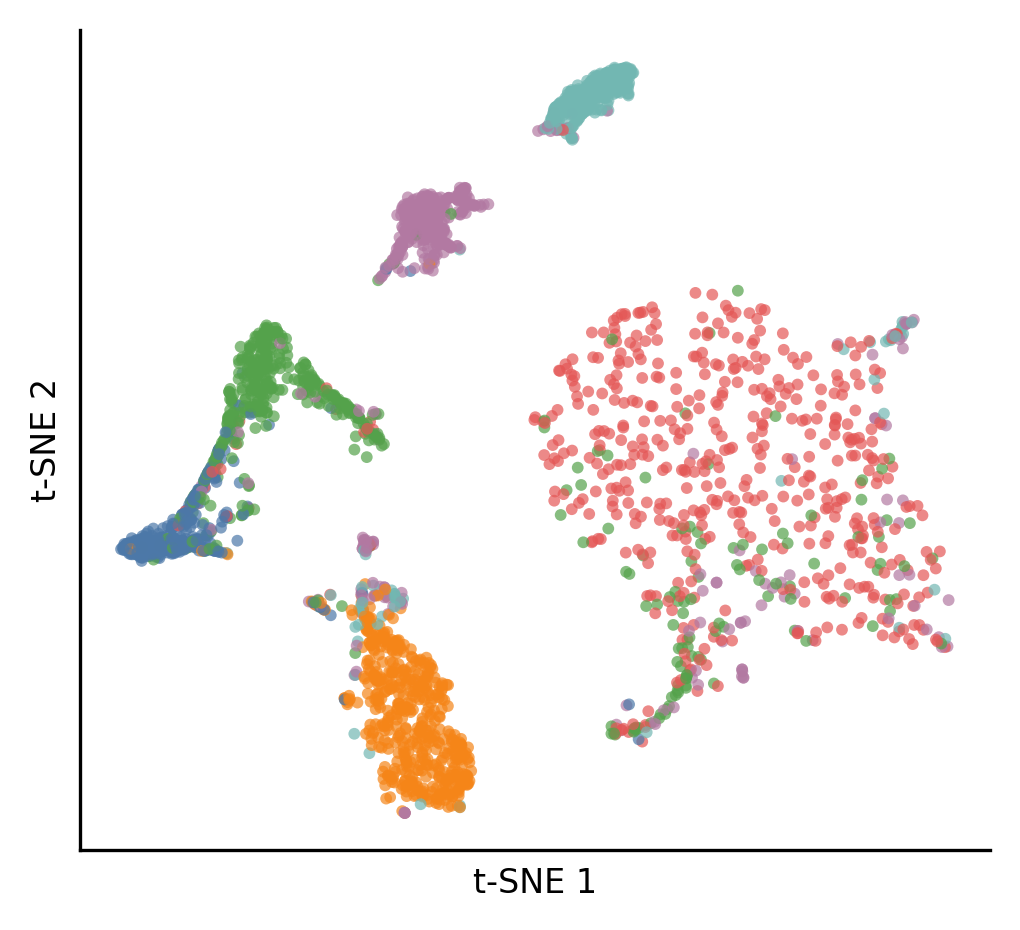

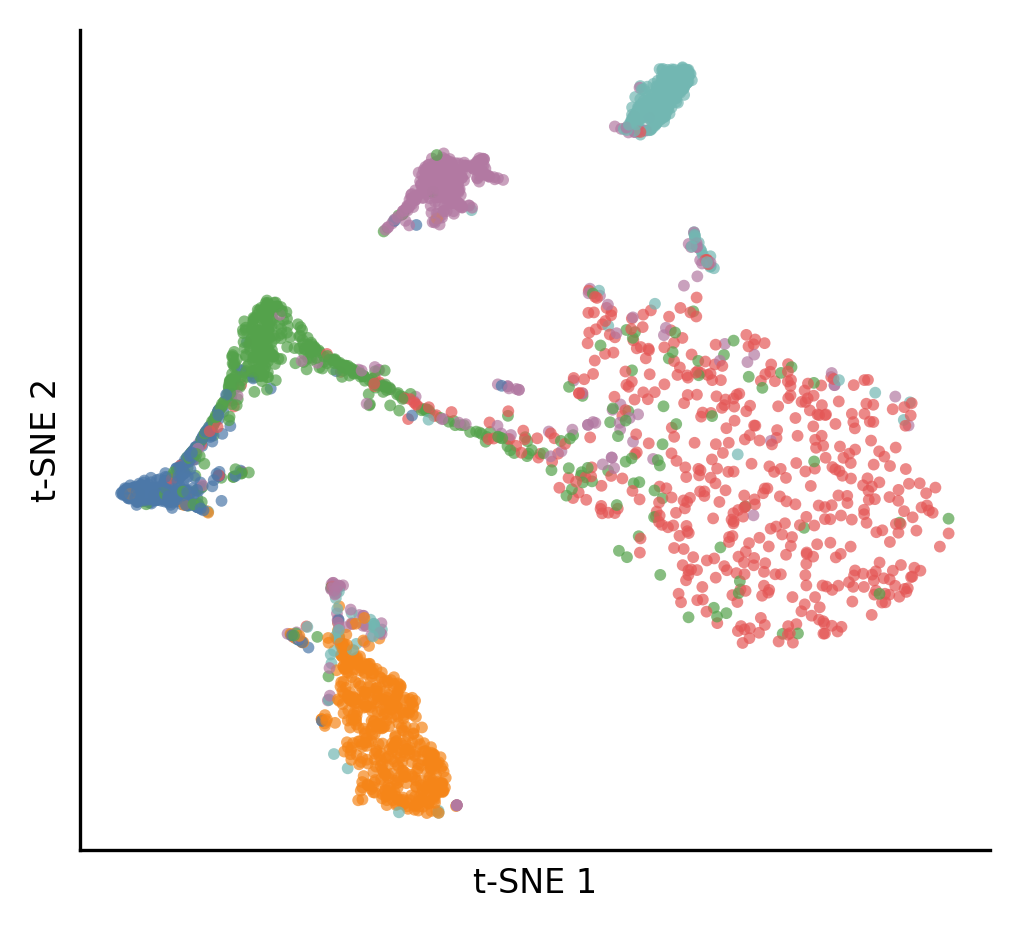

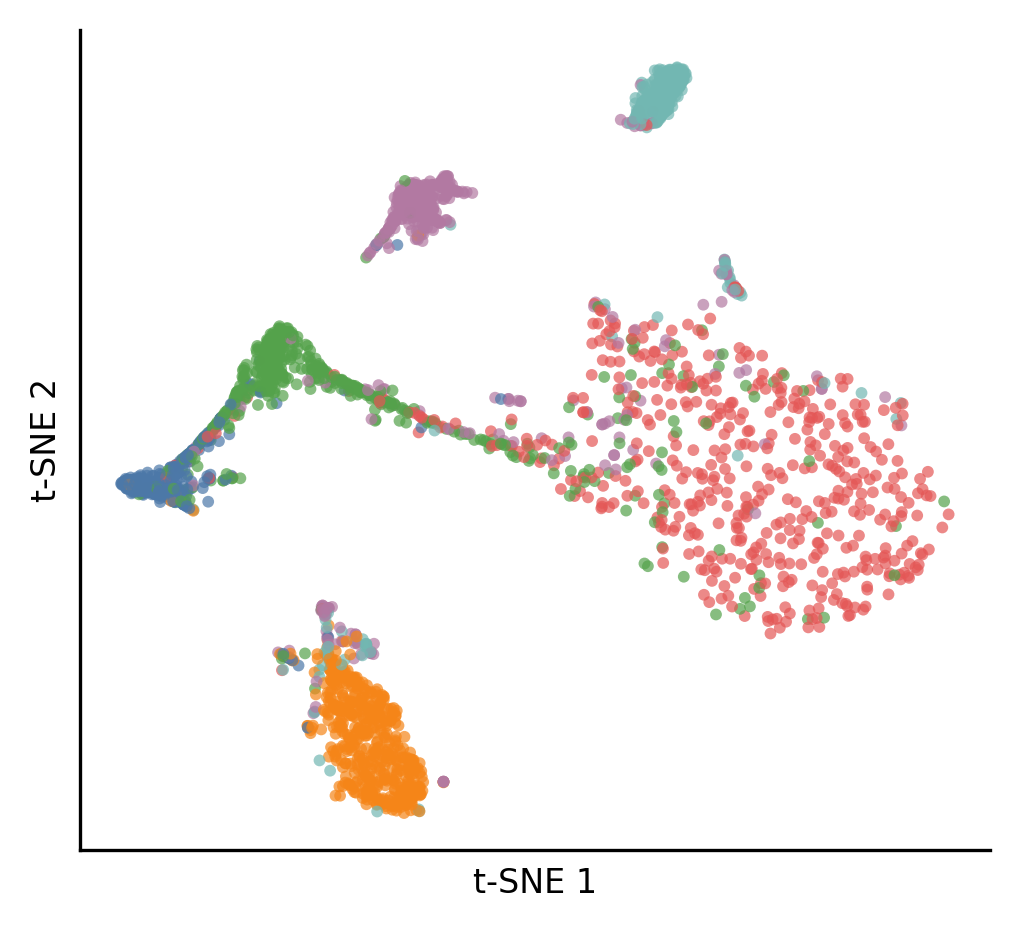

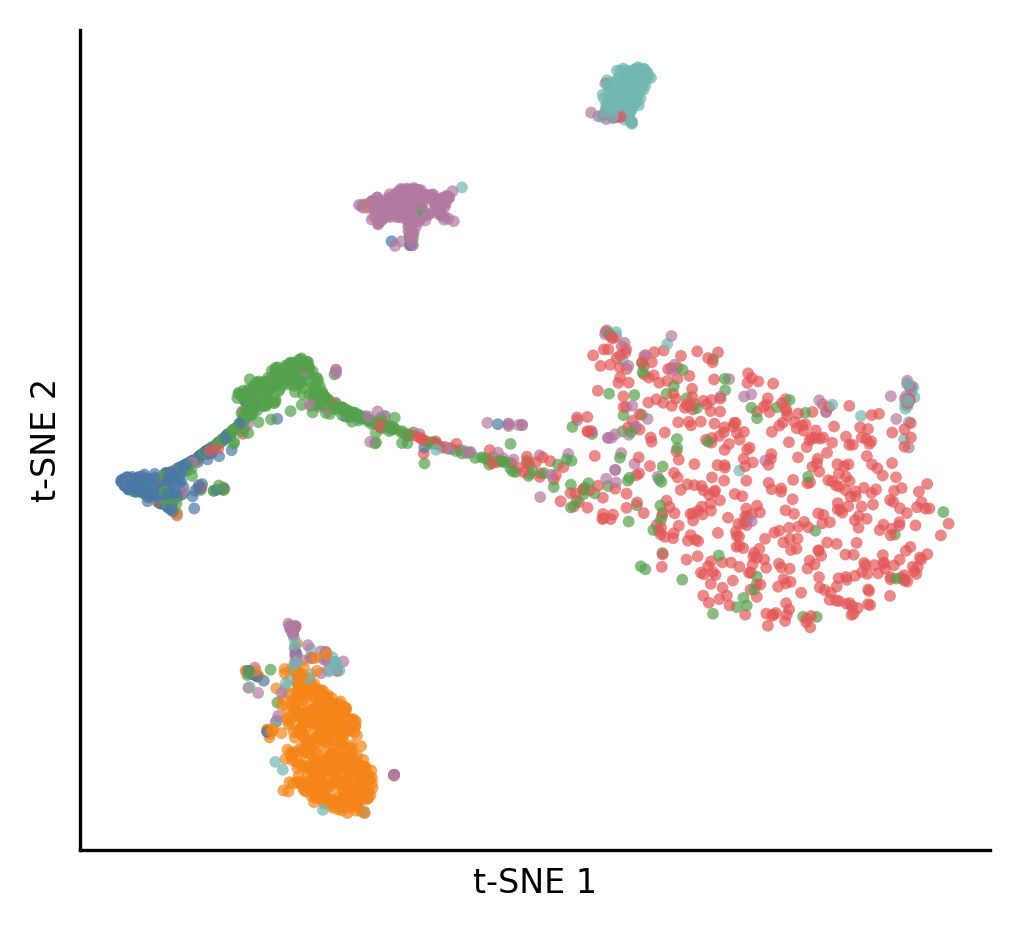

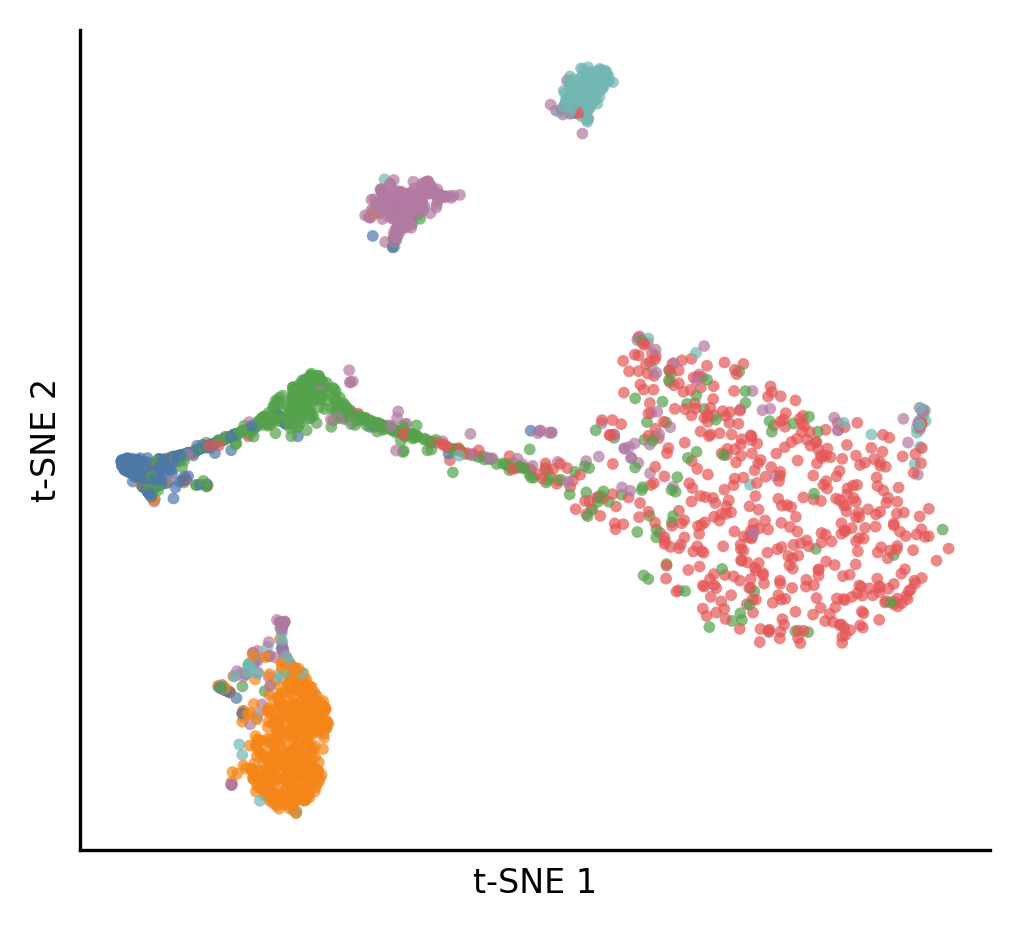

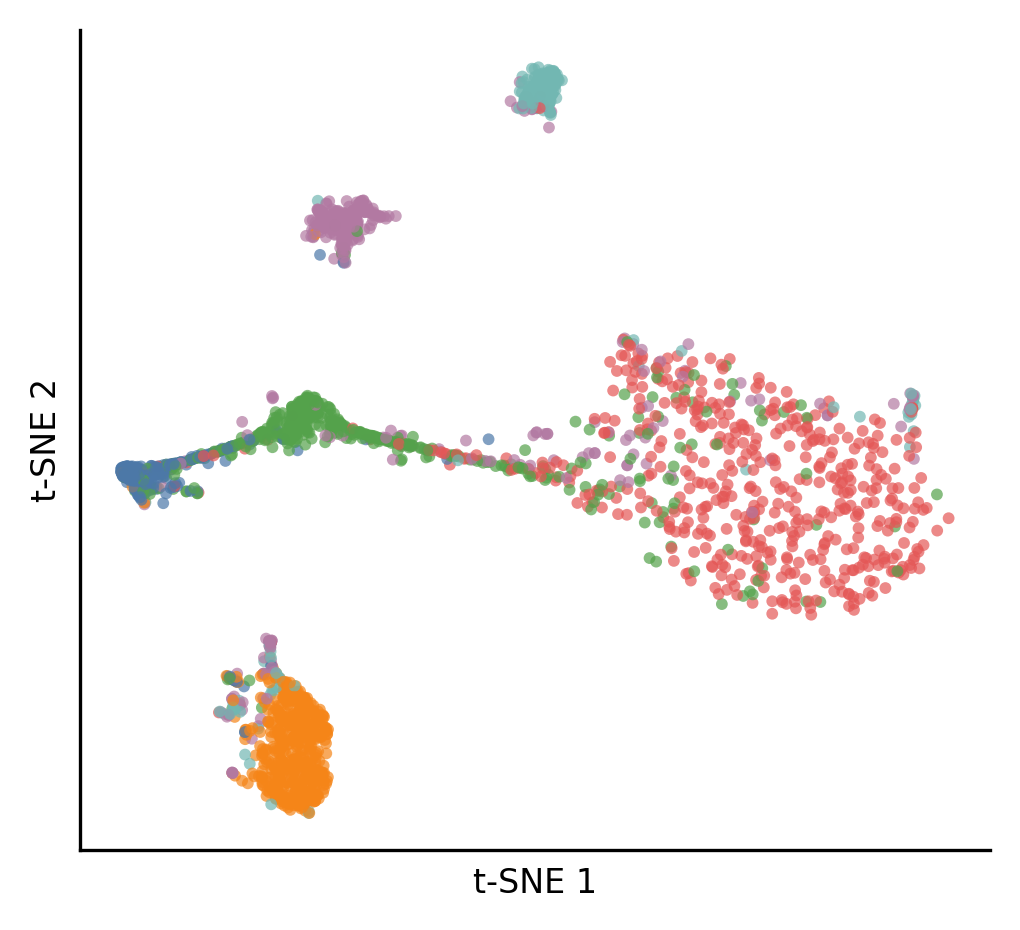

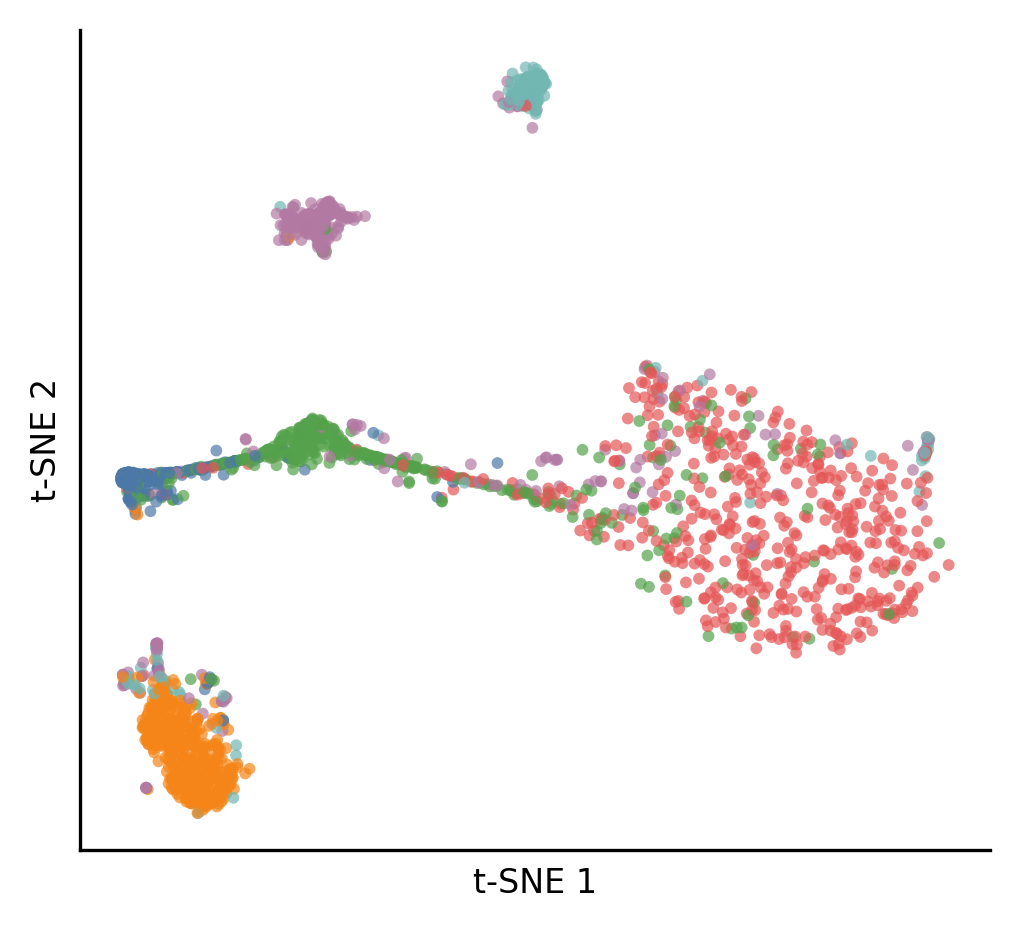

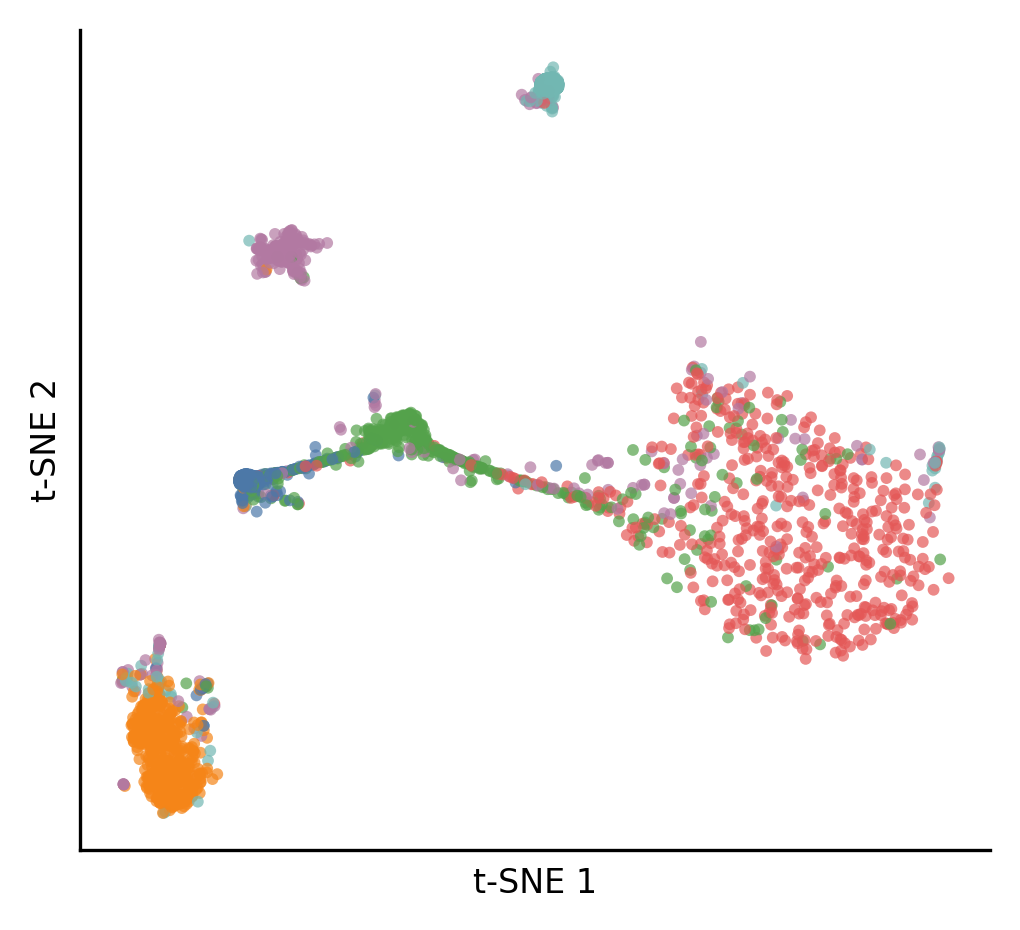

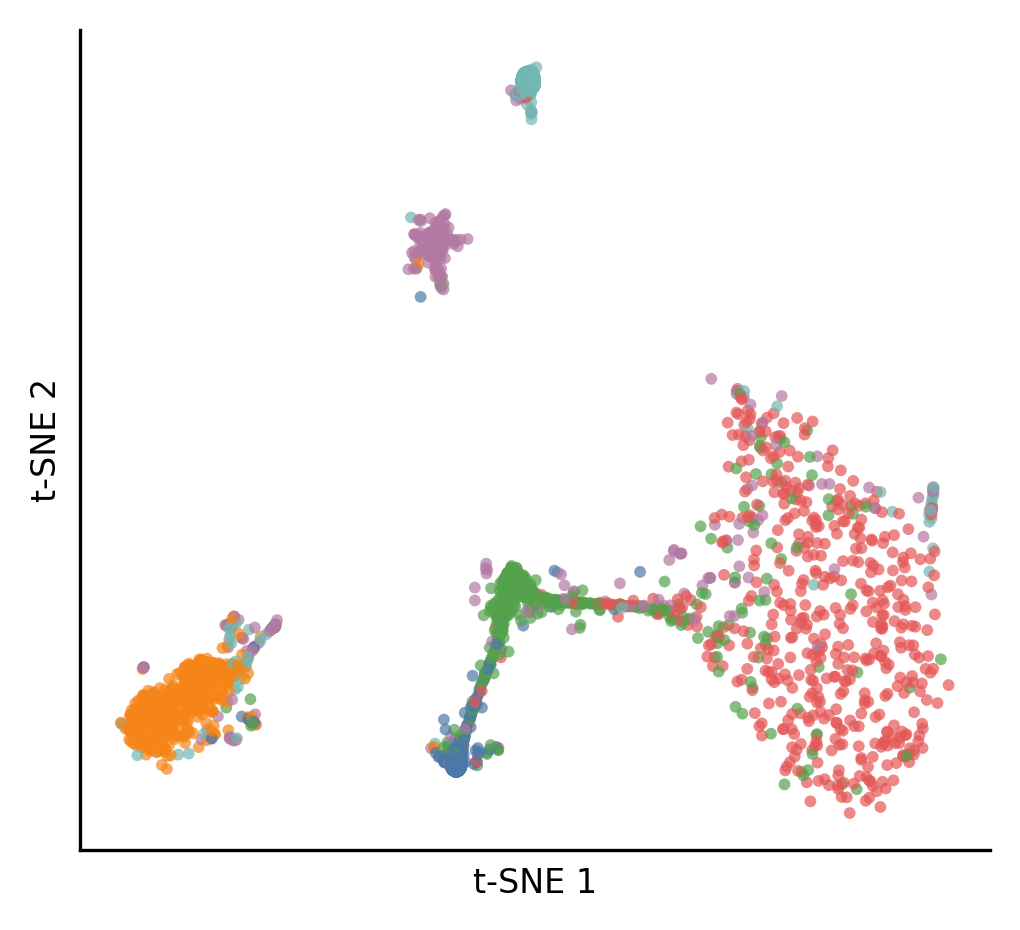

In [120]:
for i in trange(50, 550, 50):
    tsne_coordinates = calculate_tsne(
        results["embeddings"],
        perplexity=i,
        random_state=42,
    )
    tsne_results = pd.DataFrame({
    "tsne_1": tsne_coordinates[:, 0],
    "tsne_2": tsne_coordinates[:, 1],
    "label": results["labels"],
    "image_names": results["image_names"],
    "panoptic_ids": results["panoptic_ids"],
    })
    tsne_results.to_csv(f"tsne_results_final_0812_perplexity_{i}.csv", index=False)
    plot_tsne(
        coordinates=tsne_coordinates,
        labels=results["labels"],
        output_path=f"contrast_embedding_final_0812_perplexity_{i}..png",
        cutoff_number=500,
    )

Running t-SNE: samples=13751, dimensions=32, perplexity=250


In [113]:
# import pandas as pd
# tsne_results = pd.DataFrame({
#     "tsne_1": tsne_coordinates[:, 0],
#     "tsne_2": tsne_coordinates[:, 1],
#     "label": results["labels"],
#     "image_names": results["image_names"],
#     "panoptic_ids": results["panoptic_ids"],
# })
# tsne_results.to_csv("tsne_results_final_0812.csv", index=False)

(<Figure size 1050x960 with 1 Axes>,
 <Axes: xlabel='t-SNE 1', ylabel='t-SNE 2'>)

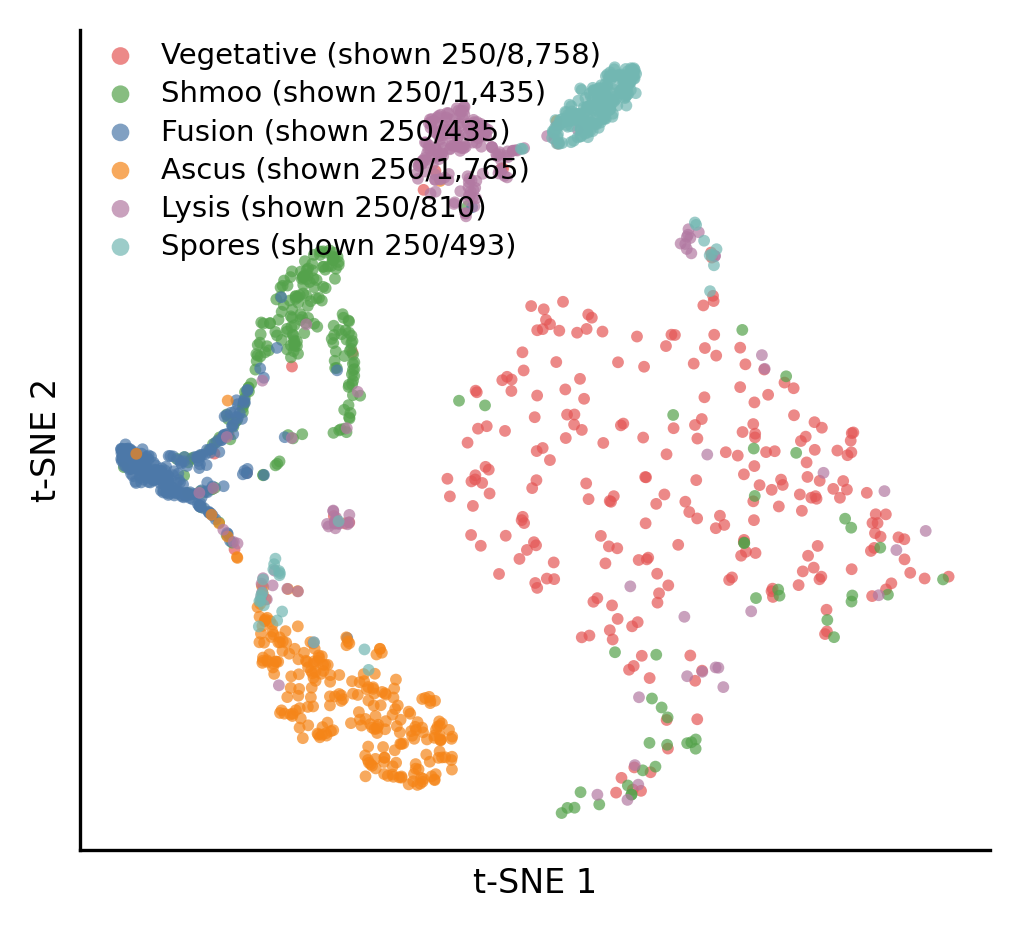

In [4]:
tsne_results = pd.read_csv("tsne_results_final_0812_perplexity_50.csv")

tsne_results.loc[(tsne_results['panoptic_ids']==6222) & (tsne_results["image_names"]=="00391_leftImg8bit.png"), "label"]=0
tsne_results.loc[(tsne_results['panoptic_ids']==6232) & (tsne_results["image_names"]=="00391_leftImg8bit.png"), "label"]=0
tsne_results.loc[(tsne_results['panoptic_ids']==6088) & (tsne_results["image_names"]=="10057_leftImg8bit.png"), "label"]=0
tsne_results.loc[(tsne_results['panoptic_ids']==6087) & (tsne_results["image_names"]=="10057_leftImg8bit.png"), "label"]=5
tsne_results.loc[(tsne_results['panoptic_ids']==6116) & (tsne_results["image_names"]=="10059_leftImg8bit.png"), "label"]=1
tsne_results.loc[(tsne_results['panoptic_ids']==6033) & (tsne_results["image_names"]=="10129_leftImg8bit.png"), "label"]=5
tsne_results.loc[(tsne_results['panoptic_ids']==6033) & (tsne_results["image_names"]=="10038_leftImg8bit.png"), "label"]=5
tsne_results.loc[(tsne_results['panoptic_ids']==6069) & (tsne_results["image_names"]=="10039_leftImg8bit.png"), "label"]=5
tsne_results.loc[(tsne_results['panoptic_ids']==6003) & (tsne_results["image_names"]=="10072_leftImg8bit.png"), "label"]=0
tsne_results.loc[(tsne_results['panoptic_ids']==2040) & (tsne_results["image_names"]=="00390_leftImg8bit.png"), "label"]=0
tsne_results.loc[(tsne_results['panoptic_ids']==2066) & (tsne_results["image_names"]=="10128_leftImg8bit.png"), "label"]=4
tsne_results.loc[(tsne_results['panoptic_ids']==3043) & (tsne_results["image_names"]=="10129_leftImg8bit.png"), "label"]=4
tsne_results.loc[(tsne_results['panoptic_ids']==3038) & (tsne_results["image_names"]=="10129_leftImg8bit.png"), "label"]=4

tsne_results.loc[(tsne_results['panoptic_ids']==2020) & (tsne_results["image_names"]=="10028_leftImg8bit.png"), "label"]=1
tsne_results.loc[(tsne_results['panoptic_ids']==2029) & (tsne_results["image_names"]=="10038_leftImg8bit.png"), "label"]=1
tsne_results.loc[(tsne_results['panoptic_ids']==2112) & (tsne_results["image_names"]=="10062_leftImg8bit.png"), "label"]=0
tsne_results.loc[(tsne_results['panoptic_ids']==2041) & (tsne_results["image_names"]=="10062_leftImg8bit.png"), "label"]=1
tsne_results.loc[(tsne_results['panoptic_ids']==2058) & (tsne_results["image_names"]=="10071_leftImg8bit.png"), "label"]=5
tsne_results.loc[(tsne_results['panoptic_ids']==2017) & (tsne_results["image_names"]=="10004_leftImg8bit.png"), "label"]=1
tsne_results.loc[(tsne_results['panoptic_ids']==2010) & (tsne_results["image_names"]=="10009_leftImg8bit.png"), "label"]=1
tsne_results.loc[(tsne_results['panoptic_ids']==2004) & (tsne_results["image_names"]=="10011_leftImg8bit.png"), "label"]=1
tsne_results.loc[(tsne_results['panoptic_ids']==2014) & (tsne_results["image_names"]=="10060_leftImg8bit.png"), "label"]=1
tsne_results.loc[(tsne_results['panoptic_ids']==2045) & (tsne_results["image_names"]=="10068_leftImg8bit.png"), "label"]=1
tsne_results.loc[(tsne_results['panoptic_ids']==2055) & (tsne_results["image_names"]=="10069_leftImg8bit.png"), "label"]=1
tsne_results.loc[(tsne_results['panoptic_ids']==2044) & (tsne_results["image_names"]=="10069_leftImg8bit.png"), "label"]=1
tsne_results.loc[(tsne_results['panoptic_ids']==2056) & (tsne_results["image_names"]=="10069_leftImg8bit.png"), "label"]=1
tsne_results.loc[(tsne_results['panoptic_ids']==2001) & (tsne_results["image_names"]=="10074_leftImg8bit.png"), "label"]=1
tsne_results.loc[(tsne_results['panoptic_ids']==2002) & (tsne_results["image_names"]=="10080_leftImg8bit.png"), "label"]=1
tsne_results.loc[(tsne_results['panoptic_ids']==2004) & (tsne_results["image_names"]=="10087_leftImg8bit.png"), "label"]=1
tsne_results.loc[(tsne_results['panoptic_ids']==2001) & (tsne_results["image_names"]=="10101_leftImg8bit.png"), "label"]=1
tsne_results.loc[(tsne_results['panoptic_ids']==2079) & (tsne_results["image_names"]=="10104_leftImg8bit.png"), "label"]=0
tsne_results.loc[(tsne_results['panoptic_ids']==2092) & (tsne_results["image_names"]=="10116_leftImg8bit.png"), "label"]=1
tsne_results.loc[(tsne_results['panoptic_ids']==2017) & (tsne_results["image_names"]=="10116_leftImg8bit.png"), "label"]=3
tsne_results.loc[(tsne_results['panoptic_ids']==2090) & (tsne_results["image_names"]=="10118_leftImg8bit.png"), "label"]=1
tsne_results.loc[(tsne_results['panoptic_ids']==2115) & (tsne_results["image_names"]=="10125_leftImg8bit.png"), "label"]=1
# OUTPUT_FIGURE = "contrast_embedding_tsne.png"
tsne_coordinates = tsne_results[
    ["tsne_1", "tsne_2"]
].to_numpy()

labels = tsne_results["label"].to_numpy()
image_names = tsne_results["image_names"]
# import pickle
# with open("contrast_embedding_selected.pkl", "rb") as f:
#     results = pickle.load(f)
# results["labels"] = labels

plot_tsne(
    coordinates=tsne_coordinates,
    labels=labels,
    output_path="contrast_embedding.png",
    cutoff_number=250,
    random_state=0,
)

(-40.0, 80.0)

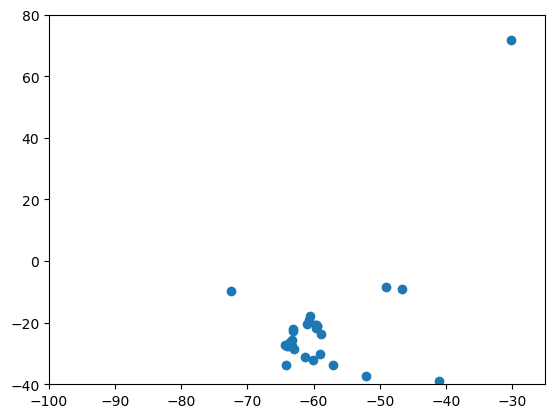

In [5]:
class_id = 6
plt.scatter(tsne_coordinates[labels==class_id, 0], tsne_coordinates[labels==class_id, 1])
seletcted = ((labels==class_id)&((image_names=="00203_leftImg8bit.png")|(image_names=="00201_leftImg8bit.png")))
plt.scatter(tsne_coordinates[seletcted, 0], tsne_coordinates[seletcted, 1])

seletcted = ((labels==class_id)&((image_names=="00424_leftImg8bit.png")|(image_names=="00427_leftImg8bit.png")))
plt.scatter(tsne_coordinates[seletcted, 0], tsne_coordinates[seletcted, 1])

plt.xlim(-100,-25)
plt.ylim(-40,80)

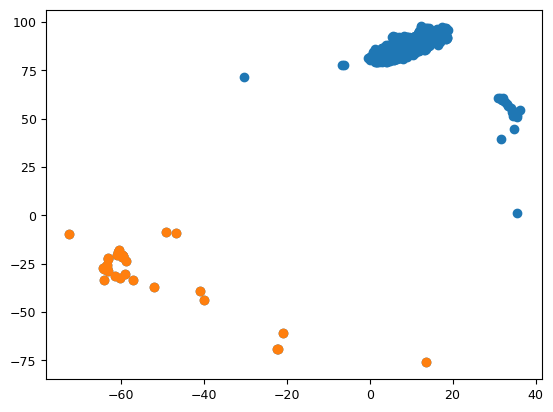

In [959]:
class_id = 6
plt.scatter(tsne_coordinates[labels==class_id, 0], tsne_coordinates[labels==class_id, 1])
seletcted = ((labels==class_id)&((tsne_coordinates[:,1]<0)))
plt.scatter(tsne_coordinates[seletcted, 0], tsne_coordinates[seletcted, 1])

In [960]:
table = pd.DataFrame([results['image_names'][seletcted], results['panoptic_ids'][seletcted]]).T
table.columns=["image_id", "p_id"]
np.unique(table.image_id)

array(['00149_leftImg8bit.png', '00247_leftImg8bit.png',
       '00468_leftImg8bit.png', '00469_leftImg8bit.png',
       '00475_leftImg8bit.png', '00480_leftImg8bit.png',
       '10003_leftImg8bit.png', '10024_leftImg8bit.png',
       '10025_leftImg8bit.png', '10043_leftImg8bit.png',
       '10055_leftImg8bit.png', '10056_leftImg8bit.png',
       '10065_leftImg8bit.png', '10066_leftImg8bit.png',
       '10071_leftImg8bit.png', '10098_leftImg8bit.png',
       '10111_leftImg8bit.png'], dtype=object)

In [961]:
table.image_id.value_counts()[0:20]

image_id
00149_leftImg8bit.png    4
10098_leftImg8bit.png    3
00469_leftImg8bit.png    3
10065_leftImg8bit.png    3
10024_leftImg8bit.png    2
10043_leftImg8bit.png    2
10025_leftImg8bit.png    2
00480_leftImg8bit.png    2
00475_leftImg8bit.png    2
00468_leftImg8bit.png    2
10111_leftImg8bit.png    2
10003_leftImg8bit.png    1
00247_leftImg8bit.png    1
10055_leftImg8bit.png    1
10056_leftImg8bit.png    1
10066_leftImg8bit.png    1
10071_leftImg8bit.png    1
Name: count, dtype: int64

                image_id  p_id
0  00149_leftImg8bit.png  6001
1  00149_leftImg8bit.png  6006
2  00149_leftImg8bit.png  6004
3  00149_leftImg8bit.png  6005


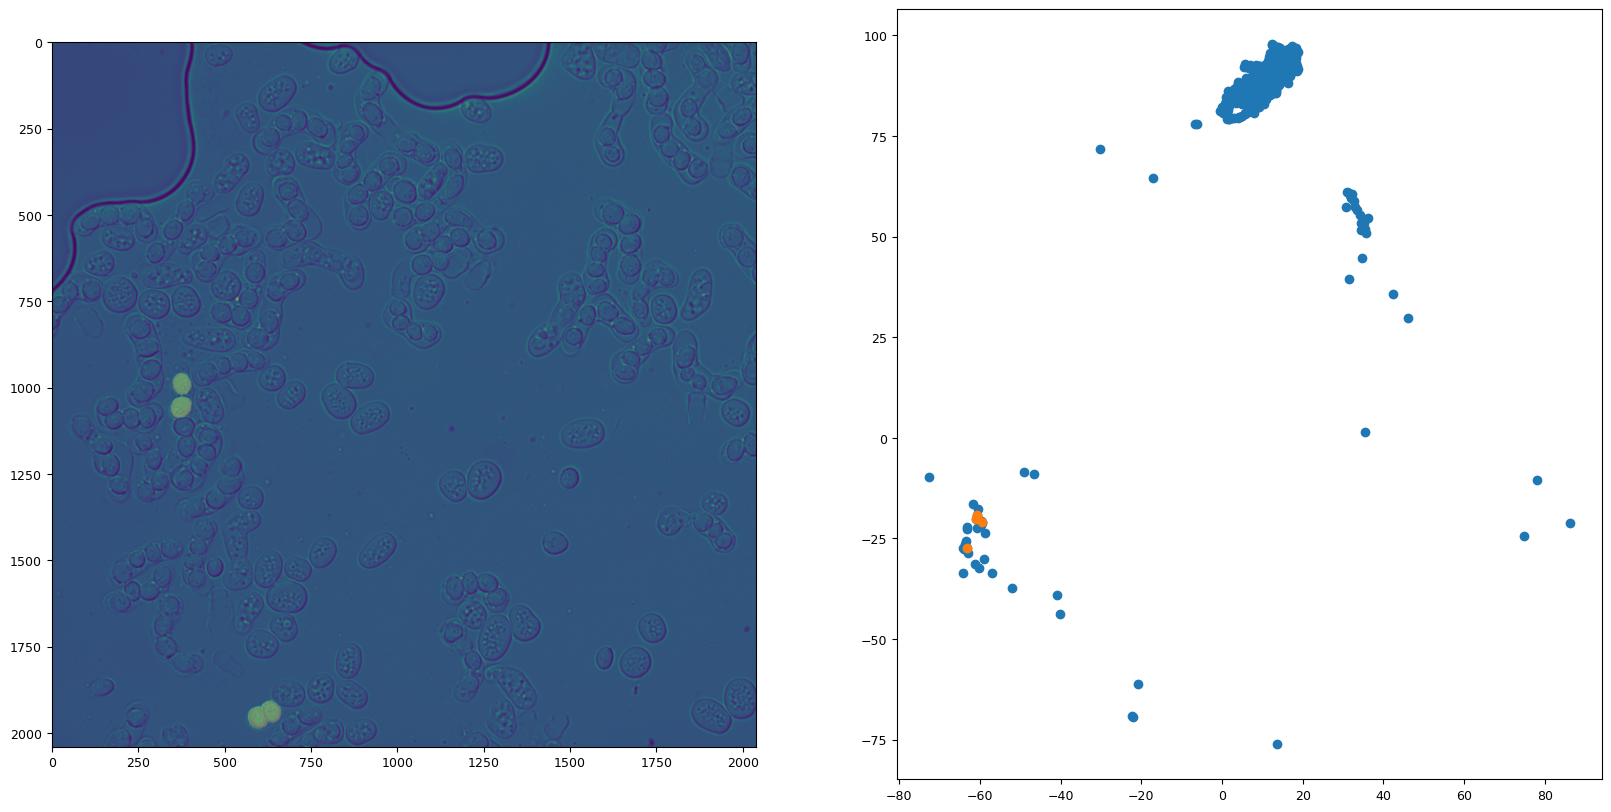

In [977]:
selected_name = "00149_leftImg8bit.png"
original_names = table["image_id"].map(get_original_name)
selected_rows = table[original_names == selected_name]
p_ids = selected_rows["p_id"].dropna().astype(int).unique()

print(table[(original_names == selected_name)&table["p_id"].isin(p_ids)])

# image = imread("/home/liwa/data/datasets/yeastcity/gtFine/test/10001_10130/"+selected_name[0:5]+"_gtFine_instanceIds.png")
# image_bg = imread("/home/liwa/data/datasets/yeastcity/leftImg8bit/test/10001_10130/"+selected_name[0:5]+"_leftImg8bit.png")

image = imread("./contrast_gt/"+selected_name[0:5]+"_gtFine_instanceIds.png")
image_bg = imread("./contrast_image/"+selected_name[0:5]+"_leftImg8bit.png")

fig ,axs = plt.subplots(1, 2, figsize=(20,10))
axs[0].imshow(image_bg[:,:,0])
axs[0].imshow(np.isin(image, p_ids), alpha=0.3)

axs[1].scatter(tsne_coordinates[results["labels"]==class_id, 0], tsne_coordinates[results["labels"]==class_id, 1])
seletcted_image = seletcted &(np.char.startswith(results["image_names"].astype(str), selected_name[:5]))

axs[1].scatter(tsne_coordinates[seletcted_image, 0], tsne_coordinates[seletcted_image, 1])

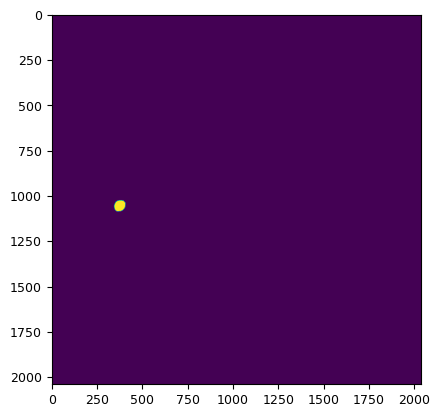

In [980]:
plt.imshow(image==6006)

In [6]:
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib.lines import Line2D


PHENOTYPE_NAMES = {
    1: "Vegetative",
    2: "Shmoo",
    3: "Fusion",
    4: "Ascus",
    5: "Lysis",
    6: "Spores",
}

PHENOTYPE_COLORS = {
    1: "#E45756",
    2: "#54A24B",
    3: "#4C78A8",
    4: "#F58518",
    5: "#B279A2",
    6: "#72B7B2",
}


def plot_tsne(
    coordinates,
    labels,
    output_path=None,
    cutoff_number=500,
    random_state=42,
    class_ids=range(1, 7),
):
    """
    Plot a publication-style t-SNE figure.

    Points are randomly subsampled within each class and then
    randomly shuffled across classes before plotting. This prevents
    one complete class from always covering another class.

    Parameters
    ----------
    coordinates : array-like, shape (n_samples, 2)
        Calculated t-SNE coordinates.

    labels : array-like, shape (n_samples,)
        Class labels.

    output_path : str or Path, optional
        Path used to save the figure.

    cutoff_number : int or None, default=500
        Maximum displayed samples per class.
        Use None to display all samples.

    random_state : int, default=42
        Seed for reproducible subsampling and drawing order.

    class_ids : iterable, default=range(1, 7)
        Classes to display.

    Returns
    -------
    fig, ax
        Matplotlib figure and axes.
    """
    coordinates = np.asarray(coordinates)
    labels = np.asarray(labels)

    if coordinates.ndim != 2 or coordinates.shape[1] != 2:
        raise ValueError(
            "coordinates must have shape (n_samples, 2)."
        )

    if labels.ndim != 1:
        labels = labels.reshape(-1)

    if coordinates.shape[0] != labels.shape[0]:
        raise ValueError(
            "coordinates and labels must contain the same "
            "number of samples."
        )

    if cutoff_number is not None and cutoff_number <= 0:
        raise ValueError(
            "cutoff_number must be a positive integer or None."
        )

    # Reproducible random-number generator
    rng = np.random.default_rng(random_state)

    fig, ax = plt.subplots(
        figsize=(3.5, 3.2),
        dpi=300,
    )

    selected_indices_list = []
    selected_labels_list = []
    legend_handles = []

    for class_id in class_ids:
        all_indices = np.flatnonzero(labels == class_id)
        total_number = len(all_indices)

        if total_number == 0:
            continue

        # Randomly select up to cutoff_number points
        if (
            cutoff_number is not None
            and total_number > cutoff_number
        ):
            selected_indices = rng.choice(
                all_indices,
                size=cutoff_number,
                replace=False,
            )
        else:
            selected_indices = all_indices

        phenotype_name = PHENOTYPE_NAMES.get(
            int(class_id),
            f"Class {class_id}",
        )

        color = PHENOTYPE_COLORS.get(
            int(class_id),
            "#808080",
        )

        selected_indices_list.append(selected_indices)

        selected_labels_list.append(
            np.full(
                len(selected_indices),
                class_id,
                dtype=labels.dtype,
            )
        )

        # Create a separate legend handle so the legend order
        # remains fixed even though point order is randomized.
        legend_handles.append(
            Line2D(
                [0],
                [0],
                marker="o",
                linestyle="none",
                markersize=4,
                markerfacecolor=color,
                markeredgecolor="none",
                alpha=0.7,
                label=(
                    f"{phenotype_name} "
                    f"(shown {len(selected_indices):,}/"
                    f"{total_number:,})"
                ),
            )
        )

    if not selected_indices_list:
        raise ValueError(
            "No samples were found for the requested class_ids."
        )

    # Combine selected points from all classes
    selected_indices = np.concatenate(
        selected_indices_list
    )
    selected_labels = np.concatenate(
        selected_labels_list
    )

    # Randomize the drawing order of individual points.
    # Points drawn later appear above points drawn earlier.
    drawing_order = rng.permutation(
        len(selected_indices)
    )

    selected_indices = selected_indices[drawing_order]
    selected_labels = selected_labels[drawing_order]

    point_colors = [
        PHENOTYPE_COLORS.get(
            int(class_id),
            "#808080",
        )
        for class_id in selected_labels
    ]

    # Plot everything in one scatter call so classes are mixed
    ax.scatter(
        coordinates[selected_indices, 0],
        coordinates[selected_indices, 1],
        s=8,
        c=point_colors,
        alpha=0.7,
        edgecolors="none",
        rasterized=True,
    )

    ax.set_xlabel(
        "t-SNE 1",
        fontsize=8,
    )
    ax.set_ylabel(
        "t-SNE 2",
        fontsize=8,
    )

    # Absolute t-SNE coordinate values are not interpretable
    ax.set_xticks([])
    ax.set_yticks([])

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(0.8)
    ax.spines["bottom"].set_linewidth(0.8)

    # ax.legend(
    #     handles=legend_handles,
    #     frameon=False,
    #     fontsize=7,
    #     markerscale=1.5,
    #     handletextpad=0.4,
    #     labelspacing=0.35,
    #     borderaxespad=0,
    #     loc="upper left",
    # )

    fig.tight_layout()

    if output_path is not None:
        output_path = Path(output_path)

        output_path.parent.mkdir(
            parents=True,
            exist_ok=True,
        )

        save_kwargs = {
            "bbox_inches": "tight",
            "pad_inches": 0.03,
            "transparent": True,
        }

        if output_path.suffix.lower() in {
            ".png",
            ".tif",
            ".tiff",
        }:
            save_kwargs["dpi"] = 600

        fig.savefig(
            output_path,
            **save_kwargs,
        )

    return fig, ax

def plot_tsne(
    coordinates,
    labels,
    output_path=None,
    cutoff_number=500,
    random_state=42,
    class_ids=range(1, 7),
):
    """
    Plot a publication-style t-SNE figure.

    Parameters
    ----------
    coordinates : array-like, shape (n_samples, 2)
        Calculated t-SNE coordinates.

    labels : array-like, shape (n_samples,)
        Class labels.

    output_path : str or Path, optional
        Save as PDF/SVG for vector output or PNG/TIFF at 600 dpi.

    cutoff_number : int or None
        Maximum number of displayed samples per class.
        Use None to display all samples.

    random_state : int
        Seed used for reproducible random subsampling.

    class_ids : iterable
        Classes to display.
    """
    coordinates = np.asarray(coordinates)
    labels = np.asarray(labels)

    if coordinates.shape[0] != labels.shape[0]:
        raise ValueError(
            "coordinates and labels must contain the same "
            "number of samples."
        )

    rng = np.random.default_rng(random_state)

    fig, ax = plt.subplots(
        figsize=(3.5, 3.2),
        dpi=300,
    )

    for class_id in class_ids:
        all_indices = np.flatnonzero(labels == class_id)
        total_number = len(all_indices)

        if total_number == 0:
            continue

        if (
            cutoff_number is not None
            and total_number > cutoff_number
        ):
            plot_indices = rng.choice(
                all_indices,
                size=cutoff_number,
                replace=False,
            )
        else:
            plot_indices = all_indices

        phenotype_name = PHENOTYPE_NAMES.get(
            int(class_id),
            f"Class {class_id}",
        )
        color = PHENOTYPE_COLORS.get(
            int(class_id),
            "#808080",
        )

        ax.scatter(
            coordinates[plot_indices, 0],
            coordinates[plot_indices, 1],
            s=8,
            color=color,
            alpha=0.7,
            edgecolors="none",
            rasterized=True,
            label=(
                f"{phenotype_name} "
                f"(shown {len(plot_indices):,}/{total_number:,})"
            ),
        )

    ax.set_xlabel("t-SNE 1", fontsize=8)
    ax.set_ylabel("t-SNE 2", fontsize=8)

    # Absolute t-SNE coordinate values are not interpretable
    ax.set_xticks([])
    ax.set_yticks([])

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(0.8)
    ax.spines["bottom"].set_linewidth(0.8)

    # ax.legend(
    #     frameon=False,
    #     fontsize=7,
    #     markerscale=1.5,
    #     handletextpad=0.4,
    #     labelspacing=0.35,
    #     borderaxespad=0,
    #     loc="upper left",
    #     # bbox_to_anchor=(1.02, 1),
    # )

    fig.tight_layout()

    if output_path is not None:
        output_path = Path(output_path)
        output_path.parent.mkdir(
            parents=True,
            exist_ok=True,
        )

        save_kwargs = {
            "bbox_inches": "tight",
            "pad_inches": 0.03,
            "transparent": True,
        }

        if output_path.suffix.lower() in {
            ".png",
            ".tif",
            ".tiff",
        }:
            save_kwargs["dpi"] = 600

        fig.savefig(
            output_path,
            **save_kwargs,
        )

    # plt.show()

    return fig, ax

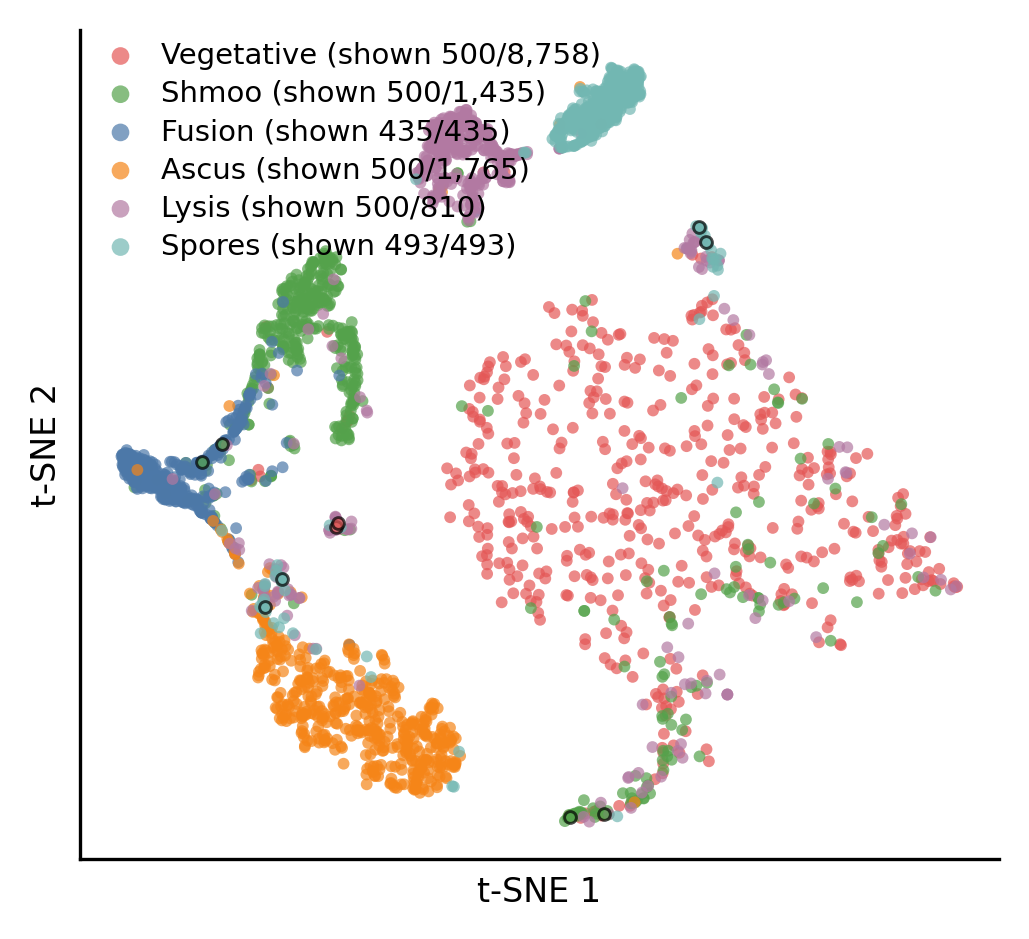

In [981]:
tsne_results = pd.read_csv("tsne_results_final_0812_perplexity_50.csv")

tsne_results.loc[(tsne_results['panoptic_ids']==6222) & (tsne_results["image_names"]=="00391_leftImg8bit.png"), "label"]=0
tsne_results.loc[(tsne_results['panoptic_ids']==6232) & (tsne_results["image_names"]=="00391_leftImg8bit.png"), "label"]=0
tsne_results.loc[(tsne_results['panoptic_ids']==6088) & (tsne_results["image_names"]=="10057_leftImg8bit.png"), "label"]=0
tsne_results.loc[(tsne_results['panoptic_ids']==6087) & (tsne_results["image_names"]=="10057_leftImg8bit.png"), "label"]=5
tsne_results.loc[(tsne_results['panoptic_ids']==6116) & (tsne_results["image_names"]=="10059_leftImg8bit.png"), "label"]=1
tsne_results.loc[(tsne_results['panoptic_ids']==6033) & (tsne_results["image_names"]=="10129_leftImg8bit.png"), "label"]=5
tsne_results.loc[(tsne_results['panoptic_ids']==6033) & (tsne_results["image_names"]=="10038_leftImg8bit.png"), "label"]=5
tsne_results.loc[(tsne_results['panoptic_ids']==6069) & (tsne_results["image_names"]=="10039_leftImg8bit.png"), "label"]=5
tsne_results.loc[(tsne_results['panoptic_ids']==6003) & (tsne_results["image_names"]=="10072_leftImg8bit.png"), "label"]=0
tsne_results.loc[(tsne_results['panoptic_ids']==2040) & (tsne_results["image_names"]=="00390_leftImg8bit.png"), "label"]=0
tsne_results.loc[(tsne_results['panoptic_ids']==2066) & (tsne_results["image_names"]=="10128_leftImg8bit.png"), "label"]=4
tsne_results.loc[(tsne_results['panoptic_ids']==3043) & (tsne_results["image_names"]=="10129_leftImg8bit.png"), "label"]=4
tsne_results.loc[(tsne_results['panoptic_ids']==3038) & (tsne_results["image_names"]=="10129_leftImg8bit.png"), "label"]=4

tsne_results.loc[(tsne_results['panoptic_ids']==2020) & (tsne_results["image_names"]=="10028_leftImg8bit.png"), "label"]=1
tsne_results.loc[(tsne_results['panoptic_ids']==2029) & (tsne_results["image_names"]=="10038_leftImg8bit.png"), "label"]=1
tsne_results.loc[(tsne_results['panoptic_ids']==2112) & (tsne_results["image_names"]=="10062_leftImg8bit.png"), "label"]=0
tsne_results.loc[(tsne_results['panoptic_ids']==2041) & (tsne_results["image_names"]=="10062_leftImg8bit.png"), "label"]=1
tsne_results.loc[(tsne_results['panoptic_ids']==2058) & (tsne_results["image_names"]=="10071_leftImg8bit.png"), "label"]=5
tsne_results.loc[(tsne_results['panoptic_ids']==2017) & (tsne_results["image_names"]=="10004_leftImg8bit.png"), "label"]=1
tsne_results.loc[(tsne_results['panoptic_ids']==2010) & (tsne_results["image_names"]=="10009_leftImg8bit.png"), "label"]=1
tsne_results.loc[(tsne_results['panoptic_ids']==2004) & (tsne_results["image_names"]=="10011_leftImg8bit.png"), "label"]=1
tsne_results.loc[(tsne_results['panoptic_ids']==2014) & (tsne_results["image_names"]=="10060_leftImg8bit.png"), "label"]=1
tsne_results.loc[(tsne_results['panoptic_ids']==2045) & (tsne_results["image_names"]=="10068_leftImg8bit.png"), "label"]=1
tsne_results.loc[(tsne_results['panoptic_ids']==2055) & (tsne_results["image_names"]=="10069_leftImg8bit.png"), "label"]=1
tsne_results.loc[(tsne_results['panoptic_ids']==2044) & (tsne_results["image_names"]=="10069_leftImg8bit.png"), "label"]=1
tsne_results.loc[(tsne_results['panoptic_ids']==2056) & (tsne_results["image_names"]=="10069_leftImg8bit.png"), "label"]=1
tsne_results.loc[(tsne_results['panoptic_ids']==2001) & (tsne_results["image_names"]=="10074_leftImg8bit.png"), "label"]=1
tsne_results.loc[(tsne_results['panoptic_ids']==2002) & (tsne_results["image_names"]=="10080_leftImg8bit.png"), "label"]=1
tsne_results.loc[(tsne_results['panoptic_ids']==2004) & (tsne_results["image_names"]=="10087_leftImg8bit.png"), "label"]=1
tsne_results.loc[(tsne_results['panoptic_ids']==2001) & (tsne_results["image_names"]=="10101_leftImg8bit.png"), "label"]=1
tsne_results.loc[(tsne_results['panoptic_ids']==2079) & (tsne_results["image_names"]=="10104_leftImg8bit.png"), "label"]=0
tsne_results.loc[(tsne_results['panoptic_ids']==2092) & (tsne_results["image_names"]=="10116_leftImg8bit.png"), "label"]=1
tsne_results.loc[(tsne_results['panoptic_ids']==2017) & (tsne_results["image_names"]=="10116_leftImg8bit.png"), "label"]=3
tsne_results.loc[(tsne_results['panoptic_ids']==2090) & (tsne_results["image_names"]=="10118_leftImg8bit.png"), "label"]=1
tsne_results.loc[(tsne_results['panoptic_ids']==2115) & (tsne_results["image_names"]=="10125_leftImg8bit.png"), "label"]=1

tsne_results.to_csv("./tsne_results_final_0812_perplexity_50_checked.csv")
# OUTPUT_FIGURE = "contrast_embedding_tsne.png"
tsne_coordinates = tsne_results[
    ["tsne_1", "tsne_2"]
].to_numpy()

labels = tsne_results["label"].to_numpy()

fig, ax = plot_tsne(
    coordinates=tsne_coordinates,
    labels=labels,
    output_path="tsne_figure.svg",
    cutoff_number=500,
    random_state=1,
)
ep_6to1 = tsne_results[(tsne_results['image_names']=="00110_leftImg8bit.png")&(tsne_results["panoptic_ids"].isin([6046, 6190]))]
ax.scatter(ep_6to1.tsne_1, ep_6to1.tsne_2, edgecolors="black", s=8, color=PHENOTYPE_COLORS[6], alpha=0.7, linewidths=0.7)

ep_1to2 = tsne_results[(tsne_results['image_names']=="00087_leftImg8bit.png")&(tsne_results["panoptic_ids"].isin([2034, 2036]))]
ax.scatter(ep_1to2.tsne_1, ep_1to2.tsne_2, edgecolors="black", s=8, color=PHENOTYPE_COLORS[2], alpha=0.7, linewidths=0.7)

ep_2to3 = tsne_results[(tsne_results['image_names']=="10057_leftImg8bit.png")&(tsne_results["panoptic_ids"].isin([2125, 2126]))] 
ax.scatter(ep_2to3.tsne_1, ep_2to3.tsne_2, edgecolors="black", s=8, color=PHENOTYPE_COLORS[2], alpha=0.7, linewidths=0.7)

ep_outline = tsne_results[(tsne_results['image_names']=="10061_leftImg8bit.png")&(tsne_results["panoptic_ids"].isin([1131, 1153]))] 
ax.scatter(ep_outline.tsne_1, ep_outline.tsne_2, edgecolors="black", s=8, color=PHENOTYPE_COLORS[1], alpha=0.7, linewidths=0.7)

ep_6to4 = tsne_results[(tsne_results['image_names']=="00149_leftImg8bit.png")&(tsne_results["panoptic_ids"].isin([6001, 6006]))] 
ax.scatter(ep_6to4.tsne_1, ep_6to4.tsne_2, edgecolors="black", s=8, color=PHENOTYPE_COLORS[6], alpha=0.7, linewidths=0.7)

plt.savefig("tsne_figure.pdf")

In [363]:

import pickle
with open("contrast_embedding_selected_3ch_crop512.pkl", "rb") as f:
    results_1 = pickle.load(f)
with open("contrast_embedding_selected_3ch_crop512_test_10001_10130.pkl", "rb") as f:
    results_2 = pickle.load(f)
results = merge_embedding_results(results_1,results_2,)

tsne_results = pd.read_csv("tsne_results_final_0812_perplexity_50_checked.csv")
aaa = tsne_results
s = (aaa.label==2) & (aaa.tsne_1 > -25) & (aaa.tsne_1<50) & (aaa.tsne_2>-30)& (aaa.tsne_2<50) 
tsne_results.loc[s, "label"] = 0
labels = tsne_results["label"].to_numpy()

Rows before removing duplicates: 14178
Rows after removing duplicates:  13751
Duplicates removed:              427


In [364]:
bbb = tsne_results[tsne_results.label==2]

Samples: 13696
Embedding dimension: 32

Class distribution:
  1: Pre-mating cell = 8758
  2: Shmoo = 1435
  3: Zygote = 435
  4: Ascus = 1765
  5: Spore = 810
  6: Lysed cell = 493


Training-set counts:
  Pre-mating cell: 6569
  Shmoo: 1076
  Zygote: 326
  Ascus: 1324
  Spore: 607
  Lysed cell: 370

Test-set counts:
  Pre-mating cell: 2189
  Shmoo: 359
  Zygote: 109
  Ascus: 441
  Spore: 203
  Lysed cell: 123

Linear-probe performance
Accuracy:          0.8893
Balanced accuracy: 0.8703
Macro-F1:          0.8295
Weighted-F1:       0.8917

Classification report:
                 precision    recall  f1-score   support

Pre-mating cell      0.955     0.914     0.934      2189
          Shmoo      0.651     0.674     0.662       359
         Zygote      0.637     0.917     0.752       109
          Ascus      0.957     0.952     0.955       441
          Spore      0.733     0.813     0.771       203
     Lysed cell      0.860     0.951     0.903       123

       accuracy                

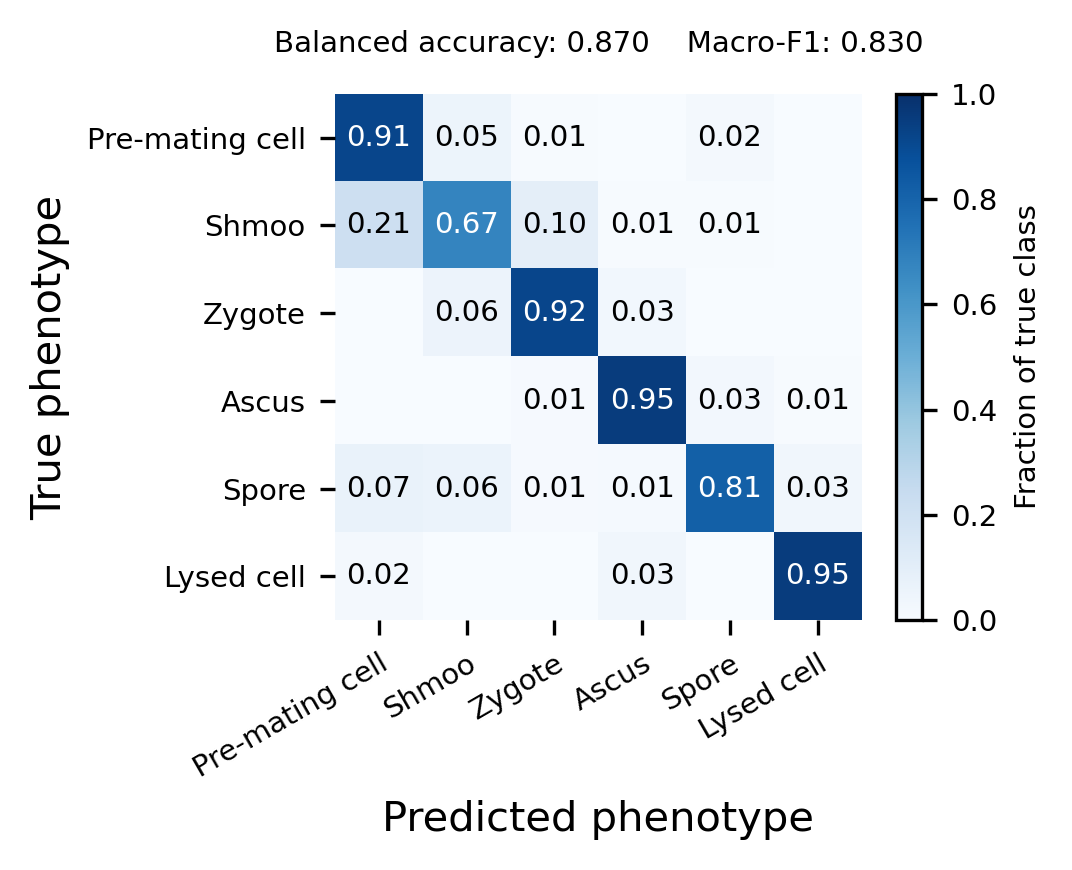


Saved figure to: linear_probe_confusion_matrix.pdf
Saved predictions to: linear_probe_predictions.csv
Saved metrics to: linear_probe_metrics.json


In [7]:
import json
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import (
    GroupShuffleSplit,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


# ============================================================
# Configuration
# ============================================================

RANDOM_STATE = 42
TEST_SIZE = 0.25

OUTPUT_FIGURE = Path("linear_probe_confusion_matrix.pdf")
OUTPUT_PREDICTIONS = Path("linear_probe_predictions.csv")
OUTPUT_METRICS = Path("linear_probe_metrics.json")

PHENOTYPE_NAMES = {
    1: "Pre-mating cell",
    2: "Shmoo",
    3: "Zygote",
    4: "Ascus",
    5: "Spore",
    6: "Lysed cell",
}

CLASS_IDS = list(PHENOTYPE_NAMES.keys())


# ============================================================
# Load embedding data
# ============================================================

# Required:
# results["embeddings"]: shape (n_samples, embedding_dim)
# results["labels"]:     shape (n_samples,)
X = np.asarray(results["embeddings"], dtype=np.float64)
y = labels # np.asarray(results["labels"]).reshape(-1)

# Optional metadata
image_ids = np.asarray(
    results.get("image_ids", np.arange(len(y)))
)

# Recommended:
# results["movie_ids"] should identify the independent movie
# or experimental group from which each cell was obtained.
groups = results.get("movie_ids", None)

if groups is not None:
    groups = np.asarray(groups).reshape(-1)


# ============================================================
# Basic validation and filtering
# ============================================================

if X.ndim != 2:
    raise ValueError(
        f"embeddings must have shape (n_samples, n_features), "
        f"but received {X.shape}"
    )

if len(X) != len(y):
    raise ValueError(
        f"Number of embeddings ({len(X)}) does not match "
        f"number of labels ({len(y)})."
    )

if len(image_ids) != len(y):
    raise ValueError(
        "image_ids must have the same length as labels."
    )

if groups is not None and len(groups) != len(y):
    raise ValueError(
        "movie_ids must have the same length as labels."
    )

# Retain only the six phenotype classes
selected = np.isin(y, CLASS_IDS)

X = X[selected]
y = y[selected]
image_ids = image_ids[selected]

if groups is not None:
    groups = groups[selected]

print(f"Samples: {len(y)}")
print(f"Embedding dimension: {X.shape[1]}")
print("\nClass distribution:")

for class_id in CLASS_IDS:
    print(
        f"  {class_id}: "
        f"{PHENOTYPE_NAMES[class_id]} = "
        f"{np.sum(y == class_id)}"
    )


# ============================================================
# Train/test split
# ============================================================

indices = np.arange(len(y))

if groups is not None:
    # Recommended: entire movies remain exclusively in either
    # the training set or the test set.
    splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=TEST_SIZE,
        random_state=RANDOM_STATE,
    )

    train_idx, test_idx = next(
        splitter.split(X, y, groups=groups)
    )

    print("\nUsing group-aware split.")
    print(
        "Training groups:",
        np.unique(groups[train_idx]),
    )
    print(
        "Test groups:",
        np.unique(groups[test_idx]),
    )

else:
    # Fallback when independent movie IDs are unavailable.
    train_idx, test_idx = train_test_split(
        indices,
        test_size=TEST_SIZE,
        random_state=RANDOM_STATE,
        stratify=y,
    )

    print(
        "\nWARNING: movie_ids were not provided. "
        "Using a stratified random cell-level split."
    )


X_train = X[train_idx]
X_test = X[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]


# Confirm that all classes appear in both subsets
print("\nTraining-set counts:")
for class_id in CLASS_IDS:
    print(
        f"  {PHENOTYPE_NAMES[class_id]}: "
        f"{np.sum(y_train == class_id)}"
    )

print("\nTest-set counts:")
for class_id in CLASS_IDS:
    print(
        f"  {PHENOTYPE_NAMES[class_id]}: "
        f"{np.sum(y_test == class_id)}"
    )

missing_train = set(CLASS_IDS) - set(np.unique(y_train))
missing_test = set(CLASS_IDS) - set(np.unique(y_test))

if missing_train:
    raise ValueError(
        f"Classes absent from training set: {missing_train}. "
        "Adjust the group split."
    )

if missing_test:
    raise ValueError(
        f"Classes absent from test set: {missing_test}. "
        "Adjust the group split."
    )


# ============================================================
# Linear probe
# ============================================================

# A linear classifier is fitted on a frozen embedding.
# No neural-network weights are updated.
linear_probe = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median"),
    ),
    (
        "scaler",
        StandardScaler(),
    ),
    (
        "classifier",
        LogisticRegression(
            penalty="l2",
            C=1.0,
            solver="lbfgs",
            max_iter=5000,
            class_weight="balanced",
            random_state=RANDOM_STATE,
        ),
    ),
])

linear_probe.fit(X_train, y_train)

y_pred = linear_probe.predict(X_test)
y_probability = linear_probe.predict_proba(X_test)


# ============================================================
# Quantitative metrics
# ============================================================

accuracy = accuracy_score(y_test, y_pred)

balanced_accuracy = balanced_accuracy_score(
    y_test,
    y_pred,
)

macro_f1 = f1_score(
    y_test,
    y_pred,
    labels=CLASS_IDS,
    average="macro",
    zero_division=0,
)

weighted_f1 = f1_score(
    y_test,
    y_pred,
    labels=CLASS_IDS,
    average="weighted",
    zero_division=0,
)

print("\nLinear-probe performance")
print(f"Accuracy:          {accuracy:.4f}")
print(f"Balanced accuracy: {balanced_accuracy:.4f}")
print(f"Macro-F1:          {macro_f1:.4f}")
print(f"Weighted-F1:       {weighted_f1:.4f}")

print("\nClassification report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=CLASS_IDS,
        target_names=[
            PHENOTYPE_NAMES[i]
            for i in CLASS_IDS
        ],
        digits=3,
        zero_division=0,
    )
)


# ============================================================
# Normalized confusion matrix
# ============================================================

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=CLASS_IDS,
)

# Normalize each row by the number of true samples.
cm_normalized = cm.astype(float) / np.maximum(
    cm.sum(axis=1, keepdims=True),
    1,
)

class_names = [
    PHENOTYPE_NAMES[class_id]
    for class_id in CLASS_IDS
]

fig, ax = plt.subplots(
    figsize=(4, 3),
    dpi=300,
)

image = ax.imshow(
    cm_normalized,
    interpolation="nearest",
    cmap="Blues",
    vmin=0,
    vmax=1,
)

colorbar = fig.colorbar(
    image,
    ax=ax,
    fraction=0.046,
    pad=0.04,
)
colorbar.ax.tick_params(labelsize=7)
colorbar.set_label(
    "Fraction of true class",
    fontsize=7,
)

ax.set_xticks(np.arange(len(CLASS_IDS)))
ax.set_yticks(np.arange(len(CLASS_IDS)))

ax.set_xticklabels(
    class_names,
    rotation=30,
    ha="right",
    rotation_mode="anchor",
    fontsize=7
)

ax.set_yticklabels(class_names, fontsize=7)

ax.set_xlabel("Predicted phenotype")
ax.set_ylabel("True phenotype")

# Add normalized values and raw sample counts.
for row in range(len(CLASS_IDS)):
    for column in range(len(CLASS_IDS)):
        value = cm_normalized[row, column]

        # Hide values close to zero
        if value < 0.005:
            continue

        text_color = (
            "white" if value > 0.55 else "black"
        )

        ax.text(
            column,
            row,
            f"{value:.2f}",
            ha="center",
            va="center",
            color=text_color,
            fontsize=7,
        )
ax.set_title(
    f"Balanced accuracy: {balanced_accuracy:.3f}    "
    f"Macro-F1: {macro_f1:.3f}",
    fontsize=7,
    pad=10,
)
# Metric summary inside the panel
metric_text = (
    f"Balanced accuracy = {balanced_accuracy:.3f}\n"
    f"Macro-F1 = {macro_f1:.3f}"
)

# ax.text(
#     1.03,
#     -0.24,
#     metric_text,
#     transform=ax.transAxes,
#     ha="right",
#     va="top",
#     fontsize=8,
# )

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()

fig.savefig(
    OUTPUT_FIGURE,
    bbox_inches="tight",
)

plt.show()


# ============================================================
# Save predictions
# ============================================================

prediction_table = pd.DataFrame({
    "sample_index": test_idx,
    "image_id": image_ids[test_idx],
    "true_label": y_test,
    "true_phenotype": [
        PHENOTYPE_NAMES[int(label)]
        for label in y_test
    ],
    "predicted_label": y_pred,
    "predicted_phenotype": [
        PHENOTYPE_NAMES[int(label)]
        for label in y_pred
    ],
    "correct": y_test == y_pred,
})

if groups is not None:
    prediction_table["movie_id"] = groups[test_idx]

# Pipeline probability-column order
probability_classes = (
    linear_probe
    .named_steps["classifier"]
    .classes_
)

for column_index, class_id in enumerate(
    probability_classes
):
    phenotype_name = PHENOTYPE_NAMES[int(class_id)]
    safe_name = (
        phenotype_name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    prediction_table[
        f"probability_{safe_name}"
    ] = y_probability[:, column_index]

prediction_table.to_csv(
    OUTPUT_PREDICTIONS,
    index=False,
)


# ============================================================
# Save metrics
# ============================================================

metrics = {
    "n_samples_total": int(len(y)),
    "n_samples_train": int(len(train_idx)),
    "n_samples_test": int(len(test_idx)),
    "embedding_dimension": int(X.shape[1]),
    "accuracy": float(accuracy),
    "balanced_accuracy": float(
        balanced_accuracy
    ),
    "macro_f1": float(macro_f1),
    "weighted_f1": float(weighted_f1),
    "class_ids": CLASS_IDS,
    "phenotype_names": PHENOTYPE_NAMES,
    "confusion_matrix_raw": cm.tolist(),
    "confusion_matrix_normalized": (
        cm_normalized.tolist()
    ),
    "split_type": (
        "group-aware"
        if groups is not None
        else "stratified-cell-level"
    ),
    "random_state": RANDOM_STATE,
}

with open(OUTPUT_METRICS, "w") as f:
    json.dump(
        metrics,
        f,
        indent=2,
    )

print(f"\nSaved figure to: {OUTPUT_FIGURE}")
print(
    f"Saved predictions to: "
    f"{OUTPUT_PREDICTIONS}"
)
print(f"Saved metrics to: {OUTPUT_METRICS}")

In [384]:
import pickle
with open("contrast_embedding_selected_3ch_crop512.pkl", "rb") as f:
    results_1 = pickle.load(f)
with open("contrast_embedding_selected_3ch_crop512_test_10001_10130.pkl", "rb") as f:
    results_2 = pickle.load(f)
results = merge_embedding_results(results_1,results_2,)

tsne_results = pd.read_csv("tsne_results_final_0812_perplexity_50_checked.csv")
labels = tsne_results["label"].to_numpy()

Rows before removing duplicates: 14178
Rows after removing duplicates:  13751
Duplicates removed:              427


In [680]:
embeddings = results['embeddings'][labels==4]
labels_selected = labels[labels==1]

In [681]:
tsne_coordinates = calculate_tsne(
    embeddings,
    perplexity=50,
    random_state=1,
)

Running t-SNE: samples=1765, dimensions=32, perplexity=50


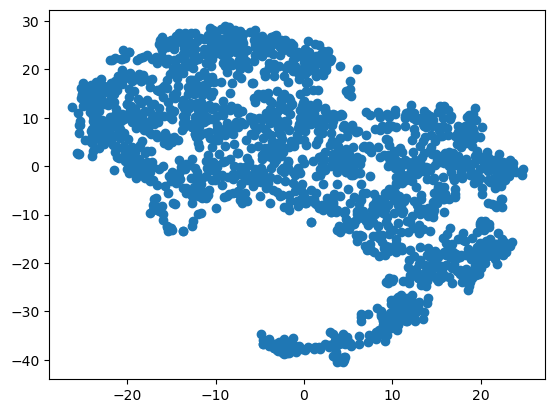

In [682]:
plt.scatter(tsne_coordinates[:,0], tsne_coordinates[:,1])

In [ ]:
class_id = 2
plt.scatter(tsne_coordinates[labels==class_id, 0], tsne_coordinates[labels==class_id, 1], alpha=0.5)

seletcted = ((labels==class_id)&((image_names=="00201_leftImg8bit.png")))
plt.scatter(tsne_coordinates[seletcted, 0], tsne_coordinates[seletcted, 1])

seletcted = ((labels==class_id)&((image_names=="00424_leftImg8bit.png")))
plt.scatter(tsne_coordinates[seletcted, 0], tsne_coordinates[seletcted, 1])

plt.xlim(-75,-25)
plt.ylim(10,60)
plt

Subtype counts:
subtype
<NA>         13360
Subtype C      192
Subtype A      107
Subtype B       92
Name: count, dtype: int64


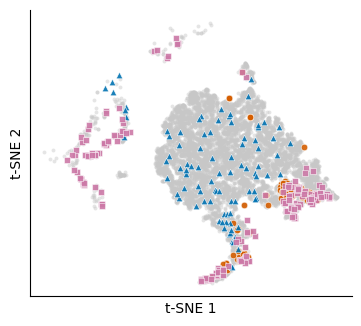

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path


# ============================================================
# 1. Publication style
# ============================================================

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.labelsize": 10,
    "axes.linewidth": 0.8,
    "legend.fontsize": 8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
})


# ============================================================
# 2. Prepare data
# ============================================================

df = tsne_results.copy()

TARGET_LABEL = 1
SHOW_COUNTS = False

required_columns = {
    "tsne_1",
    "tsne_2",
    "label",
    "image_names",
    "panoptic_ids",
}

missing = required_columns.difference(df.columns)

if missing:
    raise ValueError(
        f"Missing columns: {sorted(missing)}"
    )

# Normalize image names to avoid path and capitalization problems
df["image_key"] = (
    df["image_names"]
    .astype(str)
    .map(lambda x: Path(x).name.lower())
)


# ============================================================
# 3. Define subtype sources
# ============================================================

# Replace Subtype A/B/C with biologically meaningful names
SUBTYPE_SOURCES = {
    "Subtype A": [
        "00201_leftImg8bit.png",
        "00203_leftImg8bit.png",
    ],
    "Subtype B": [
        "00422_leftImg8bit.png",
        "00424_leftImg8bit.png",
        "00427_leftImg8bit.png",
    ],
    "Subtype C": [
        "10052_leftImg8bit.png",
        "10053_leftImg8bit.png",
        "10056_leftImg8bit.png",
        # "10117_leftImg8bit.png",
        # "10112_leftImg8bit.png",
        # "10114_leftImg8bit.png",
        # "10118_leftImg8bit.png",
        # "10106_leftImg8bit.png",
        # "10109_leftImg8bit.png",
        
    ],
}

# Color-blind-friendly colors
SUBTYPE_COLORS = {
    "Subtype A": "#D55E00",
    "Subtype B": "#0072B2",
    "Subtype C": "#CC79A7",
}

# Use both colors and shapes to distinguish subtypes
SUBTYPE_MARKERS = {
    "Subtype A": "o",   # circle
    "Subtype B": "^",   # triangle
    "Subtype C": "s",   # square
}


# ============================================================
# 4. Assign subtype annotations
# ============================================================

df["subtype"] = pd.NA

for subtype, image_patterns in SUBTYPE_SOURCES.items():

    image_patterns = [
        str(pattern).lower()
        for pattern in image_patterns
    ]

    # Supports both full filenames and partial string matching
    source_mask = df["image_key"].apply(
        lambda name: any(
            pattern in name
            for pattern in image_patterns
        )
    )

    # Only annotate objects belonging to the target coarse class
    subtype_mask = (
        source_mask
        & df["label"].eq(TARGET_LABEL)
    )

    # Detect image names assigned to more than one subtype
    overlap = (
        subtype_mask
        & df["subtype"].notna()
    )

    if overlap.any():
        duplicated = df.loc[
            overlap,
            [
                "image_names",
                "panoptic_ids",
                "subtype",
            ],
        ]

        raise ValueError(
            "Some points matched multiple subtypes:\n"
            f"{duplicated}"
        )

    df.loc[subtype_mask, "subtype"] = subtype


# ============================================================
# 5. Check subtype matching
# ============================================================

print("Subtype counts:")
print(df["subtype"].value_counts(dropna=False))

for subtype in SUBTYPE_SOURCES:
    if not df["subtype"].eq(subtype).any():
        print(
            f"Warning: no samples matched for '{subtype}'"
        )


# ============================================================
# 6. Define plotting masks
# ============================================================

target_mask = df["label"].eq(TARGET_LABEL)

unannotated_mask = (
    target_mask
    & df["subtype"].isna()
)


# ============================================================
# 7. Plot
# ============================================================

fig, ax = plt.subplots(
    figsize=(3.5, 3.2),
    constrained_layout=True,
)


# Unannotated samples within the target class
ax.scatter(
    df.loc[unannotated_mask, "tsne_1"],
    df.loc[unannotated_mask, "tsne_2"],
    s=8,
    color="#C7C7C7",
    alpha=0.45,
    marker="o",
    linewidths=0,
    rasterized=True,
    # label=f"Other class-{TARGET_LABEL} cells",
    zorder=1,
)


# Highlight known subtypes
for subtype in SUBTYPE_SOURCES:

    mask = df["subtype"].eq(subtype)
    n_samples = int(mask.sum())

    if n_samples == 0:
        continue

    if SHOW_COUNTS:
        legend_label = (
            f"{subtype} ($n$ = {n_samples})"
        )
    else:
        legend_label = subtype

    ax.scatter(
        df.loc[mask, "tsne_1"],
        df.loc[mask, "tsne_2"],
        s=22,
        color=SUBTYPE_COLORS[subtype],
        marker=SUBTYPE_MARKERS[subtype],
        alpha=0.90,
        edgecolors="white",
        linewidths=0.4,
        rasterized=True,
        label=legend_label,
        zorder=3,
    )


# ============================================================
# 8. Axes formatting
# ============================================================

# Region displayed in this subtype panel

ax.set_xlabel("t-SNE 1")
ax.set_ylabel("t-SNE 2")

# Coordinates have no direct biological units
ax.set_xticks([])
ax.set_yticks([])

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_linewidth(0.8)
ax.spines["bottom"].set_linewidth(0.8)

ax.set_aspect(
    "equal",
    adjustable="box",
)

# Keep legend outside the data region
# ax.legend(
#     loc="upper left",
#     bbox_to_anchor=(1.02, 1.0),
#     borderaxespad=0,
#     frameon=False,
#     handletextpad=0.5,
#     labelspacing=0.5,
#     markerscale=1.15,
# )

# ax.set_xlim(-70, -38)
# ax.set_ylim(22, 55)

# ============================================================
# 9. Save publication files
# ============================================================

fig.savefig(
    "class_2_subtype_distribution.pdf",
    bbox_inches="tight",
    dpi=600,
    transparent=True,
)

fig.savefig(
    "class_2_subtype_distribution.png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white",
)

fig.savefig(
    "class_2_subtype_distribution.svg",
    bbox_inches="tight",
    transparent=True,
)